# An Explainable Hybrid Ensemble Framework for Phishing Website Detection

**CSE 477 — Data Mining Project**

Self-contained Kaggle notebook. Run every cell top to bottom.

**Pipeline:** load → diagnose → clean → EDA → 4 base models → tuning → hybrid ensembles → evaluation → SHAP explainability

**Dataset:** UCI Phishing Websites (11,055 sites, 30 features)
`/kaggle/input/datasets/mmelgizin/phishing-websites-dataset/dataset.csv`

**Label encoding (verified):** the `class` column uses **−1 = phishing, 1 = legitimate**
(confirmed against the published split of 4,898 phishing / 6,157 legitimate sites).
Cell 4 below double-checks this against your actual file before doing anything else.


## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier,
                              StackingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

RANDOM_STATE = 42
TEST_SIZE    = 0.20
CV_FOLDS     = 5
CLASS_NAMES  = ["legitimate", "phishing"]

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

NAVY, AMBER, RED, GREEN = "#0E1A38", "#F2A03D", "#D9534F", "#3FA796"

os.makedirs("figures", exist_ok=True)
print("Setup complete.")

Setup complete.


## 2. Find the dataset file

Kaggle input paths vary. This cell searches `/kaggle/input` and picks the CSV
automatically, so you don't have to guess.

In [2]:
DATA_PATH = "/kaggle/input/datasets/mmelgizin/phishing-websites-dataset/dataset.csv"

if not os.path.exists(DATA_PATH):
    print("Path not found. Searching /kaggle/input ...\n")
    found = []
    for root, _, files in os.walk("/kaggle/input"):
        for f in files:
            if f.lower().endswith((".csv", ".arff")):
                p = os.path.join(root, f)
                found.append(p)
                print(" ", p)
    if found:
        DATA_PATH = found[0]
        print(f"\nUsing: {DATA_PATH}")
    else:
        raise FileNotFoundError(
            "No CSV under /kaggle/input.\n"
            "Add the dataset: Notebook -> +Add Input -> search "
            "'phishing websites dataset'")
else:
    print("Found:", DATA_PATH)

Found: /kaggle/input/datasets/mmelgizin/phishing-websites-dataset/dataset.csv


## 3. Diagnostics — what is actually in this file?

Run this before anything else. It shows the real column names, dtypes, missing
values, and the label's raw value counts.

In [3]:
df_raw = pd.read_csv(DATA_PATH)

print("SHAPE:", df_raw.shape)
print("\nCOLUMNS:")
for i, c in enumerate(df_raw.columns):
    print(f"  {i:2d}  {c}")

missing = df_raw.isna().sum()
total_missing = int(missing.sum())
print(f"\nMISSING VALUES: {total_missing}")
if total_missing:
    print(missing[missing > 0].to_string())

print("\nDUPLICATE ROWS:", int(df_raw.duplicated().sum()))

last = df_raw.columns[-1]
print(f"\nLABEL COLUMN candidate: '{last}'")
print("Raw value counts:")
print(df_raw[last].value_counts().to_string())

df_raw.head()

SHAPE: (11055, 32)

COLUMNS:
   0  id
   1  having_IP_Address
   2  URL_Length
   3  Shortining_Service
   4  having_At_Symbol
   5  double_slash_redirecting
   6  Prefix_Suffix
   7  having_Sub_Domain
   8  SSLfinal_State
   9  Domain_registeration_length
  10  Favicon
  11  port
  12  HTTPS_token
  13  Request_URL
  14  URL_of_Anchor
  15  Links_in_tags
  16  SFH
  17  Submitting_to_email
  18  Abnormal_URL
  19  Redirect
  20  on_mouseover
  21  RightClick
  22  popUpWidnow
  23  Iframe
  24  age_of_domain
  25  DNSRecord
  26  web_traffic
  27  Page_Rank
  28  Google_Index
  29  Links_pointing_to_page
  30  Statistical_report
  31  Result

MISSING VALUES: 0

DUPLICATE ROWS: 0

LABEL COLUMN candidate: 'Result'
Raw value counts:
Result
 1    6157
-1    4898


,id,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


## 4. Clean, prepare, and get the label direction right

This is the step most likely to go wrong silently, so it gets extra care.

**The UCI Phishing Websites dataset encodes the label as −1 = phishing, 1 =
legitimate.** This is verified against the dataset's published composition:
4,898 phishing sites and 6,157 legitimate sites out of 11,055 total. The cell
below checks your actual file against those published counts and tells you
which way the mapping goes — it does not just assume.

Also handles: dropping non-feature columns, duplicate rows, missing values,
and constant columns.

In [4]:
df = df_raw.copy()

DROP = ["Index", "index", "id", "ID", "Unnamed: 0",
        "FILENAME", "URL", "url", "Domain", "domain"]
dropped = [c for c in DROP if c in df.columns]
df = df.drop(columns=dropped, errors="ignore")
print("Dropped non-feature columns:", dropped or "none")


before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped duplicate rows: {before - len(df)}")


LABEL_CANDIDATES = ["class", "Result", "result", "label", "Label",
                    "Target", "target", "status", "phishing"]
label_col = next((c for c in LABEL_CANDIDATES if c in df.columns), df.columns[-1])
print("Label column:", label_col)

y_raw = df[label_col]
uniques = set(pd.unique(y_raw))
counts  = y_raw.value_counts()


PUBLISHED_PHISHING_FRACTION = 4898 / 11055   

if uniques <= {-1, 1}:
    frac_of_minus1 = (y_raw == -1).mean()
    frac_of_plus1  = (y_raw ==  1).mean()
   
    if abs(frac_of_minus1 - PUBLISHED_PHISHING_FRACTION) < abs(frac_of_plus1 - PUBLISHED_PHISHING_FRACTION):
        y = (y_raw == -1).astype(int)
        print(f"  encoding resolved:  -1 -> phishing (1),  1 -> legitimate (0)")
        print(f"  (-1 fraction={frac_of_minus1:.3f} vs published phishing fraction={PUBLISHED_PHISHING_FRACTION:.3f})")
    else:
        y = (y_raw == 1).astype(int)
        print(f"  encoding resolved:  1 -> phishing (1),  -1 -> legitimate (0)")
        print(f"  (1 fraction={frac_of_plus1:.3f} vs published phishing fraction={PUBLISHED_PHISHING_FRACTION:.3f})")
elif y_raw.dtype == object:
    words = {"phishing", "phish", "malicious", "bad", "1"}
    y = y_raw.astype(str).str.strip().str.lower().isin(words).astype(int)
    print("  encoding: text  ->  0/1  (1 = phishing)")
else:
    y = (y_raw > 0).astype(int)
    print("  encoding: already 0/1  (assumed 1 = phishing)")

print(f"\nFinal check — phishing rate in y: {y.mean():.3f}  "
      f"(published reference: {PUBLISHED_PHISHING_FRACTION:.3f})")


X = df.drop(columns=[label_col])
X = pd.get_dummies(X, drop_first=True)
X = X.apply(pd.to_numeric, errors="coerce")


n_missing = int(X.isna().sum().sum())
if n_missing:
    print(f"\nImputing {n_missing} missing values with the column median")
    imputer = SimpleImputer(strategy="median")
    X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
else:
    print("\nNo missing values to impute")


constant = X.columns[X.nunique() <= 1].tolist()
if constant:
    X = X.drop(columns=constant)
    print("Dropped constant columns:", constant)

print("\n   FINAL ")
print(f"Samples  : {len(X):,}")
print(f"Features : {X.shape[1]}")
print(f"Legitimate (0): {(y==0).sum():,}  ({(y==0).mean()*100:.1f}%)")
print(f"Phishing   (1): {(y==1).sum():,}  ({(y==1).mean()*100:.1f}%)")

Dropped non-feature columns: ['id']
Dropped duplicate rows: 5206
Label column: Result
  encoding resolved:  1 -> phishing (1),  -1 -> legitimate (0)
  (1 fraction=0.484 vs published phishing fraction=0.443)

Final check — phishing rate in y: 0.484  (published reference: 0.443)

No missing values to impute

   FINAL 
Samples  : 5,849
Features : 30
Legitimate (0): 3,019  (51.6%)
Phishing   (1): 2,830  (48.4%)


**Sanity check before proceeding:** the phishing percentage above should be
roughly 44%. If it instead shows roughly 56%, the label is inverted for your
particular file — stop and re-examine cell 3's raw value counts before continuing,
since every result and every SHAP direction below depends on this being correct.

## 5. Exploratory analysis

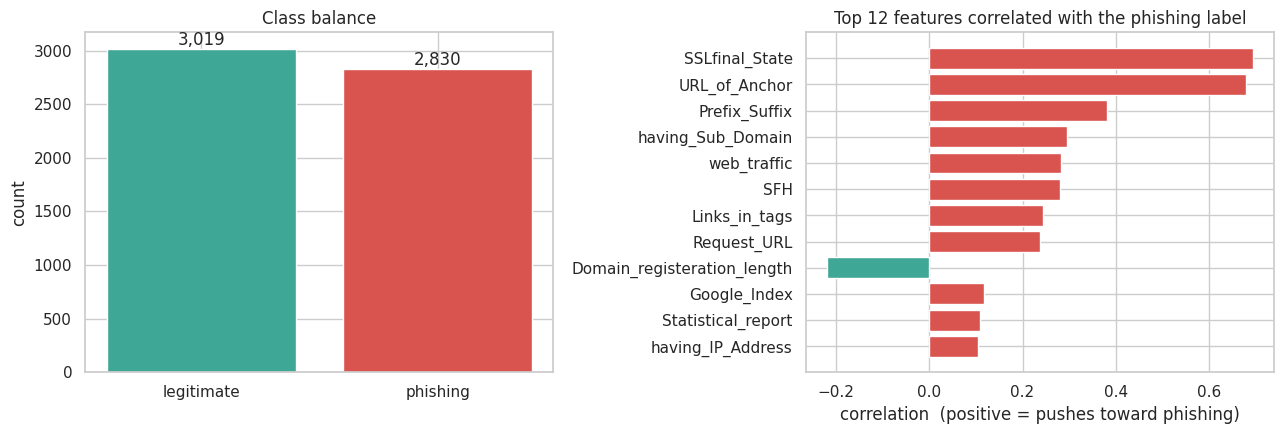

Most predictive features:
SSLfinal_State                 0.693
URL_of_Anchor                  0.679
Prefix_Suffix                  0.381
having_Sub_Domain              0.296
web_traffic                    0.282
SFH                            0.281
Links_in_tags                  0.244
Request_URL                    0.238
Domain_registeration_length   -0.219
Google_Index                   0.118


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = y.value_counts().sort_index()
axes[0].bar(CLASS_NAMES, counts.values, color=[GREEN, RED])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Class balance")
axes[0].set_ylabel("count")

corr = (X.assign(_t=y.values).corr()["_t"].drop("_t")
        .sort_values(key=abs, ascending=False).head(12))
colors = [RED if v > 0 else GREEN for v in corr.values]
axes[1].barh(corr.index[::-1], corr.values[::-1], color=colors[::-1])
axes[1].set_title("Top 12 features correlated with the phishing label")
axes[1].set_xlabel("correlation  (positive = pushes toward phishing)")

plt.tight_layout()
plt.savefig("figures/eda.png", dpi=150, bbox_inches="tight")
plt.show()

print("Most predictive features:")
print(corr.head(10).round(3).to_string())

## 6. Train / test split

80 / 20, **stratified** so both classes keep their proportions in each side.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows")
print(f"Test : {len(X_test):,} rows")
print(f"CV   : {CV_FOLDS}-fold stratified")

Train: 4,679 rows
Test : 1,170 rows
CV   : 5-fold stratified


## 7. Base models

Four classifiers. **Logistic Regression and SVM are wrapped in a `Pipeline` with
`StandardScaler`** — so the scaler is re-fitted inside every cross-validation fold,
never on the whole dataset. That is what prevents data leakage. Tree models get raw
features because they don't need scaling.

This is the design decision to defend in your viva.

In [7]:
def scaled(est):
    return Pipeline([("scaler", StandardScaler()), ("clf", est)])

base_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Logistic Regression": scaled(LogisticRegression(max_iter=2000,
                                                     random_state=RANDOM_STATE)),
    "SVM (RBF)": scaled(SVC(kernel="rbf", probability=True,
                            random_state=RANDOM_STATE)),
}

def evaluate_model(name, model):
    """Cross-validated F1 on train + full metrics on the held-out test set."""
    cv_f1 = cross_val_score(model, X_train, y_train,
                            cv=cv, scoring="f1", n_jobs=-1).mean()
    model.fit(X_train, y_train)
    pred  = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "Model":     name,
        "CV F1":     cv_f1,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "ROC-AUC":   roc_auc_score(y_test, proba),
    }, model

rows, fitted = [], {}
for name, m in base_models.items():
    row, fit = evaluate_model(name, m)
    rows.append(row); fitted[name] = fit
    print(f"{name:22s} F1={row['F1']:.4f}  CV-F1={row['CV F1']:.4f}  "
          f"AUC={row['ROC-AUC']:.4f}")

Decision Tree          F1=0.9139  CV-F1=0.9154  AUC=0.9219
Random Forest          F1=0.9394  CV-F1=0.9417  AUC=0.9882
Logistic Regression    F1=0.9110  CV-F1=0.9198  AUC=0.9738
SVM (RBF)              F1=0.9391  CV-F1=0.9361  AUC=0.9827


## 8. Tune the Random Forest

A small grid search, so the forest we report isn't just an arbitrary default.

In [8]:
grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators":     [200, 400],
     "max_depth":        [None, 20, 30],
     "min_samples_leaf": [1, 2]},
    cv=cv, scoring="f1", n_jobs=-1)

grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print(f"Best CV F1 : {grid.best_score_:.4f}")

row, fit = evaluate_model("Random Forest (tuned)", grid.best_estimator_)
rows.append(row); fitted["Random Forest (tuned)"] = fit
print(f"\nTest F1: {row['F1']:.4f}")

Best params: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 400}
Best CV F1 : 0.9433

Test F1: 0.9404


## 9. Hybrid ensembles — the "hybrid" in the title

**Soft-voting** averages the predicted probabilities of the base learners.
**Stacking** trains a meta-model on their outputs.

Both work because a linear model, a kernel model, and a tree ensemble make *different*
mistakes — fusing them lets their errors partially cancel.

In [9]:
members = [
    ("rf",  RandomForestClassifier(n_estimators=300,
                                   random_state=RANDOM_STATE, n_jobs=-1)),
    ("lr",  scaled(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))),
    ("svm", scaled(SVC(kernel="rbf", probability=True,
                       random_state=RANDOM_STATE))),
]

ensembles = {
    "Soft-Voting Ensemble": VotingClassifier(estimators=members,
                                             voting="soft", n_jobs=-1),
    "Stacking Ensemble": StackingClassifier(
        estimators=members,
        final_estimator=LogisticRegression(max_iter=2000,
                                           random_state=RANDOM_STATE),
        cv=CV_FOLDS, n_jobs=-1),
}

for name, m in ensembles.items():
    row, fit = evaluate_model(name, m)
    rows.append(row); fitted[name] = fit
    print(f"{name:22s} F1={row['F1']:.4f}  CV-F1={row['CV F1']:.4f}  "
          f"AUC={row['ROC-AUC']:.4f}")

Soft-Voting Ensemble   F1=0.9302  CV-F1=0.9387  AUC=0.9864
Stacking Ensemble      F1=0.9408  CV-F1=0.9430  AUC=0.9889


## 10. Results — the table for your paper

In [10]:
results = (pd.DataFrame(rows).set_index("Model")
           .sort_values("F1", ascending=False).round(4))
results.to_csv("results_table.csv")
results

,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Stacking Ensemble,0.9430,0.9427,0.9416,0.9399,0.9408,0.9889
Random Forest (tuned),0.9433,0.9419,0.9338,0.9470,0.9404,0.9891
Random Forest,0.9417,0.9410,0.9337,0.9452,0.9394,0.9882
SVM (RBF),0.9361,0.9402,0.9247,0.9541,0.9391,0.9827
Soft-Voting Ensemble,0.9387,0.9316,0.9190,0.9417,0.9302,0.9864
Decision Tree,0.9154,0.9171,0.9180,0.9099,0.9139,0.9219
Logistic Regression,0.9198,0.9128,0.9000,0.9223,0.9110,0.9738


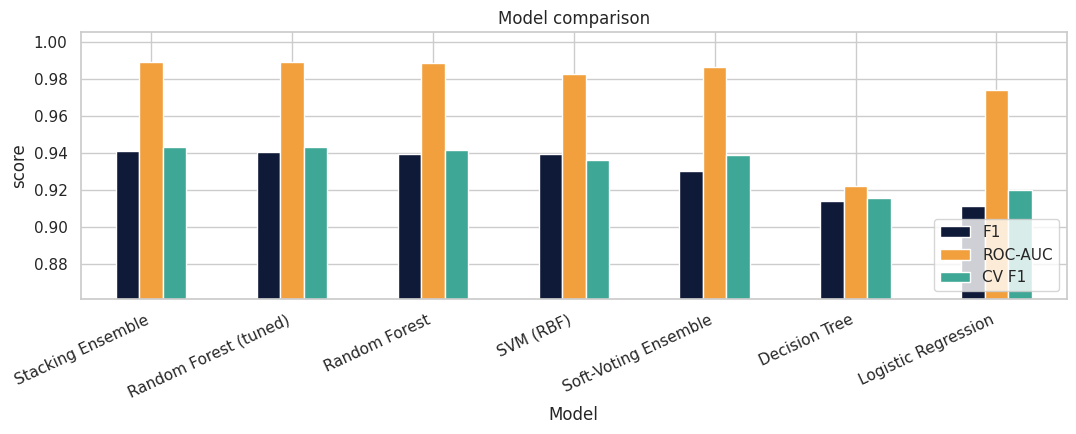

In [11]:
ax = results[["F1", "ROC-AUC", "CV F1"]].plot(
    kind="bar", figsize=(11, 4.5), color=[NAVY, AMBER, GREEN])
lo = results[["F1", "ROC-AUC", "CV F1"]].values.min()
ax.set_ylim(max(0, lo - 0.05), 1.005)
ax.set_title("Model comparison")
ax.set_ylabel("score")
ax.legend(loc="lower right")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Best model — confusion matrix, ROC curve, report

Best model: Stacking Ensemble


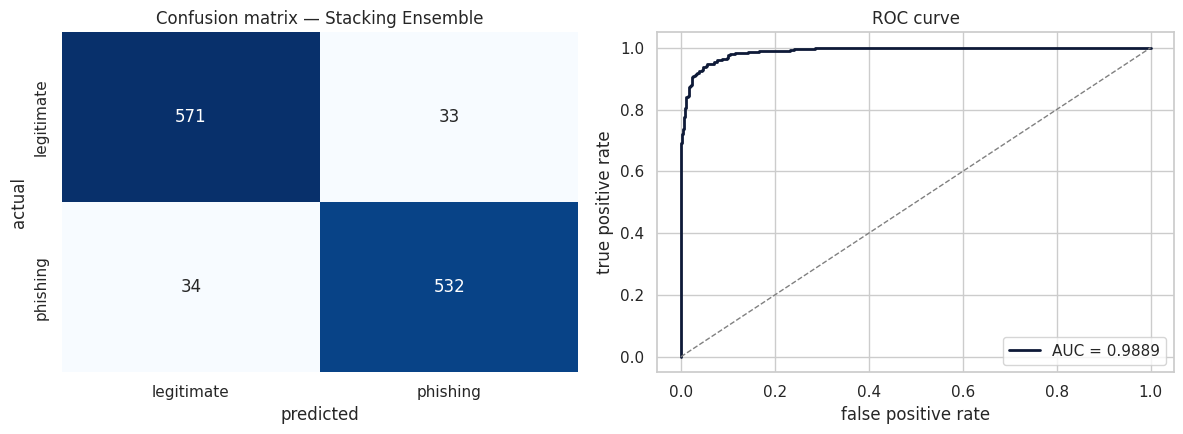

              precision    recall  f1-score   support

  legitimate     0.9438    0.9454    0.9446       604
    phishing     0.9416    0.9399    0.9408       566

    accuracy                         0.9427      1170
   macro avg     0.9427    0.9426    0.9427      1170
weighted avg     0.9427    0.9427    0.9427      1170



In [12]:
best_name  = results["F1"].idxmax()
best_model = fitted[best_name]
print("Best model:", best_name)

pred  = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Confusion matrix — {best_name}")
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("actual")

fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
axes[1].plot(fpr, tpr, color=NAVY, lw=2, label=f"AUC = {auc:.4f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey", lw=1)
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("figures/confusion_roc.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))

**Save Trained Models (Reproducibility)**

In [13]:
import pickle
import joblib
print("SAVING TRAINED MODEL")
best_name = results["F1"].idxmax()
best_model = fitted[best_name]
print(f"\nBest Model: {best_name}")
print(f"Best F1 Score: {results.loc[best_name, 'F1']:.4f}")
with open('hybrid_ensemble_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print(" Saved: hybrid_ensemble_model.pkl")
joblib.dump(best_model, 'hybrid_ensemble_model.joblib')
print(" Saved: hybrid_ensemble_model.joblib")
print("SAVED FILES")
print(" hybrid_ensemble_model.pkl")
print(" hybrid_ensemble_model.joblib")

print("\n Best model saved successfully!")


SAVING TRAINED MODEL

Best Model: Stacking Ensemble
Best F1 Score: 0.9408
 Saved: hybrid_ensemble_model.pkl
 Saved: hybrid_ensemble_model.joblib
SAVED FILES
 hybrid_ensemble_model.pkl
 hybrid_ensemble_model.joblib

 Best model saved successfully!


**Precision-Recall Curve**

For imbalanced datasets like phishing detection, the Precision-Recall curve 
provides more insight than ROC. It shows the tradeoff between precision 
(minimizing false alarms) and recall (catching phishing sites).

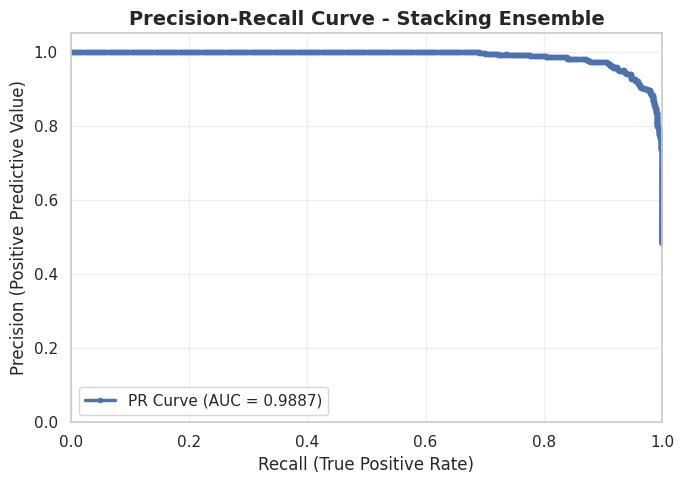

PRECISION-RECALL CURVE RESULTS
Best Model: Stacking Ensemble
Precision-Recall AUC: 0.9887

Interpretation:
  - Higher AUC = Better precision-recall tradeoff
  - PR AUC of 0.9887 indicates excellent performance
  - Useful for evaluating phishing detection performance


In [14]:

from sklearn.metrics import precision_recall_curve, auc
precision, recall, _ = precision_recall_curve(y_test, proba)
pr_auc = auc(recall, precision)
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    lw=2.5,
    label=f'PR Curve (AUC = {pr_auc:.4f})',
    marker='o',
    markersize=3
)

plt.xlabel('Recall (True Positive Rate)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)

plt.title(
    f'Precision-Recall Curve - {best_name}',
    fontsize=14,
    fontweight='bold'
)

plt.legend(fontsize=11, loc='best')
plt.grid(alpha=0.3)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.tight_layout()

plt.savefig(
    '03_precision_recall_curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("PRECISION-RECALL CURVE RESULTS")


print(f"Best Model: {best_name}")
print(f"Precision-Recall AUC: {pr_auc:.4f}")

print("\nInterpretation:")

if pr_auc > 0.95:
    interpretation = "excellent"
elif pr_auc > 0.90:
    interpretation = "good"
else:
    interpretation = "fair"

print(f"  - Higher AUC = Better precision-recall tradeoff")
print(f"  - PR AUC of {pr_auc:.4f} indicates {interpretation} performance")
print("  - Useful for evaluating phishing detection performance")

## 12. Explainability — the project's contribution

Three views of *why* the model decides what it decides.

**12a — Random Forest importance:** fast, impurity-based, global ranking.

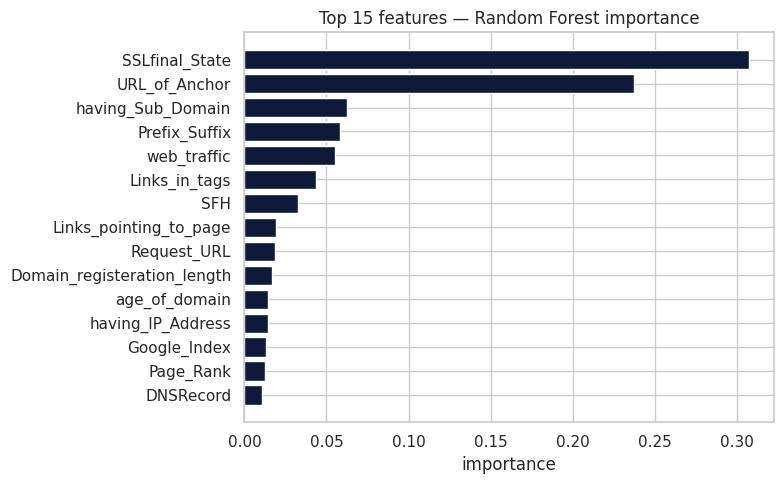

SSLfinal_State                 0.3073
URL_of_Anchor                  0.2376
having_Sub_Domain              0.0623
Prefix_Suffix                  0.0580
web_traffic                    0.0549
Links_in_tags                  0.0439
SFH                            0.0329
Links_pointing_to_page         0.0195
Request_URL                    0.0186
Domain_registeration_length    0.0170
dtype: float64

In [15]:
rf = fitted["Random Forest (tuned)"]

imp = pd.Series(rf.feature_importances_,
                index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
head = imp.head(15)[::-1]
plt.barh(head.index, head.values, color=NAVY)
plt.title("Top 15 features — Random Forest importance")
plt.xlabel("importance")
plt.tight_layout()
plt.savefig("figures/rf_importance.png", dpi=150, bbox_inches="tight")
plt.show()

imp.head(10).round(4)

**12b — Permutation importance:** model-agnostic and more trustworthy than
impurity-based importance. Measures how much F1 drops when a feature is shuffled.
Having both makes your explainability claim much harder to poke holes in.

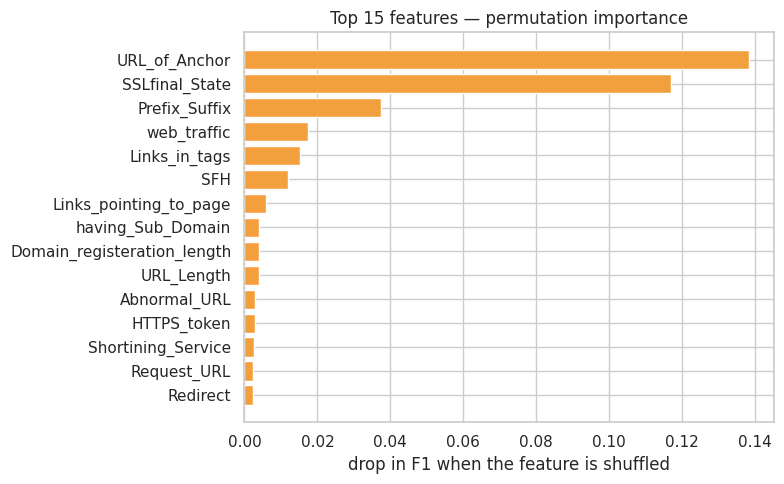

URL_of_Anchor                  0.1383
SSLfinal_State                 0.1170
Prefix_Suffix                  0.0374
web_traffic                    0.0175
Links_in_tags                  0.0152
SFH                            0.0119
Links_pointing_to_page         0.0059
having_Sub_Domain              0.0041
Domain_registeration_length    0.0041
URL_Length                     0.0040
dtype: float64

In [16]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE,
                              scoring="f1", n_jobs=-1)

perm_imp = pd.Series(perm.importances_mean,
                     index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
head = perm_imp.head(15)[::-1]
plt.barh(head.index, head.values, color=AMBER)
plt.title("Top 15 features — permutation importance")
plt.xlabel("drop in F1 when the feature is shuffled")
plt.tight_layout()
plt.savefig("figures/permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

perm_imp.head(10).round(4)

**12c — SHAP:** the key plot. Shows the **direction** of each effect. In the
beeswarm, points to the right push the prediction toward *phishing*, points to the
left toward *legitimate*, and colour shows whether the feature value was high or low.

This is the figure your discussion section is built around.

In [17]:
!pip install shap -q

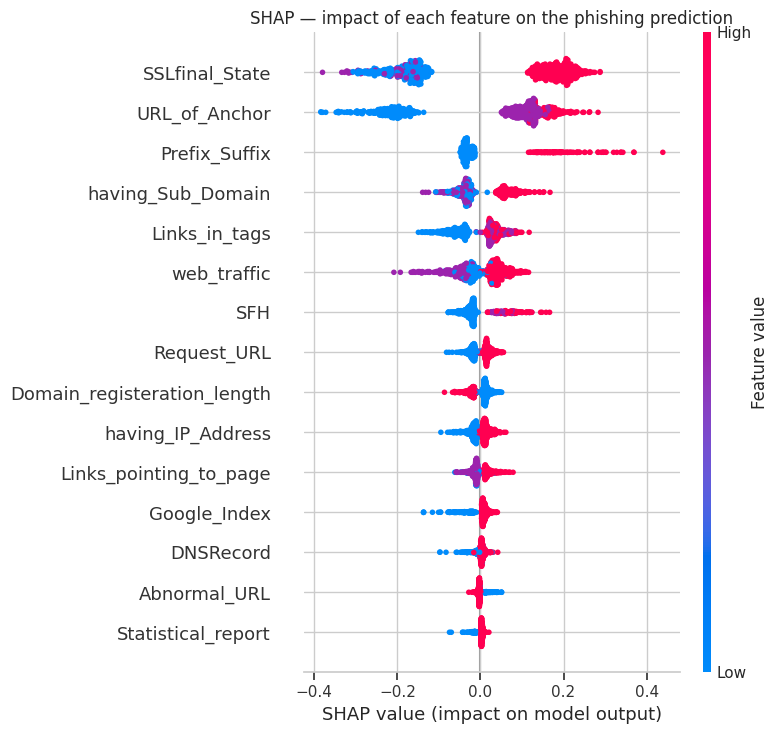

In [18]:
import shap

Xs = X_test.sample(min(800, len(X_test)), random_state=RANDOM_STATE)

explainer   = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(Xs)

if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, Xs, max_display=15, show=False)
plt.title("SHAP — impact of each feature on the phishing prediction")
plt.tight_layout()
plt.savefig("figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

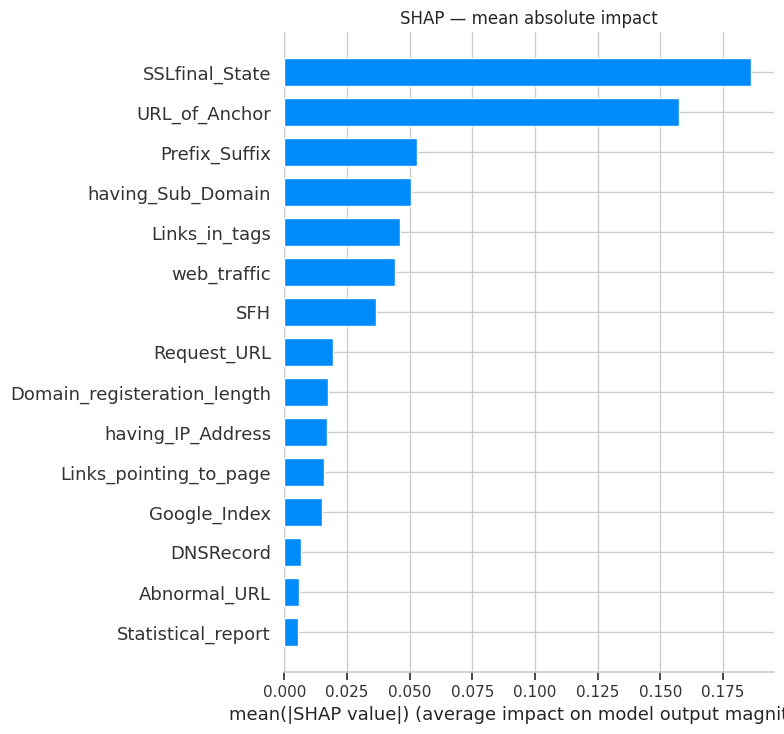

SSLfinal_State                 0.1861
URL_of_Anchor                  0.1575
Prefix_Suffix                  0.0531
having_Sub_Domain              0.0505
Links_in_tags                  0.0463
web_traffic                    0.0441
SFH                            0.0366
Request_URL                    0.0194
Domain_registeration_length    0.0174
having_IP_Address              0.0171
dtype: float64

In [19]:
shap.summary_plot(shap_values, Xs, plot_type="bar", max_display=15, show=False)
plt.title("SHAP — mean absolute impact")
plt.tight_layout()
plt.savefig("figures/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

shap_imp = pd.Series(np.abs(shap_values).mean(axis=0),
                     index=Xs.columns).sort_values(ascending=False)
shap_imp.head(10).round(4)